# A whispering gallery mode from the circle to the limaçon of Pascal

A circular microdisk keeps light in whispering gallery modes (WGM) with
enormous Q, but it emits the little that leaks evenly in all directions,
which makes it hard to collect. Deforming the disk opens a way out.
Wiersig and Hentschel (Phys. Rev. Lett. **100**, 033901 (2008)) proposed
the **limaçon of Pascal**,

$$\rho(\varphi) = R\,(1 + \varepsilon\cos\varphi),$$

and showed that at $\varepsilon \approx 0.43$ a semiconductor disk keeps
a high Q and emits mostly into one direction.

This notebook follows one WGM of a GaAs disk with the FDFD of notebook
[66](66_fdfd_basics.ipynb) as the disk is deformed from the circle to
$\varepsilon = 0.43$:

1. the shapes and the computational cell,
2. the WGM of the circle against the exact mode,
3. the mode traced through the deformation: wavelength, Q, directionality,
4. near fields,
5. far fields,
6. the other modes of the $\varepsilon = 0.43$ cavity,
7. a check of the deformed cavity with the FDTD (ring-down).

Parameters: GaAs with $n = 3.3$ at a near-infrared wavelength around
1.55 µm, disk radius R = 1.8 µm (so the WGM with azimuthal number m = 20
sits near 1.54 µm), the field along the disk axis $E_z$ (the polarization
called TM in the microdisk literature). Lengths in µm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import analytical as an
from pyoptics import fdfd, fdtd
from pyoptics.fdtd import plot as fplot

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
t_start = time.perf_counter()

n_gaas, R, m_wgm = 3.3, 1.8, 20
gaas = fdtd.Medium.from_index(n_gaas)
h = 0.0225                                   # about 21 cells per wavelength in GaAs
N = int(round(6.8/h)) | 1                    # odd: the Ez nodes are symmetric about x = 0 and y = 0
grid = fdtd.Grid((N*h, N*h), h, center=(h/2, h/2))
rho_ff = 2.8                                 # circle of the far-field expansion
eps_list = [round(e, 2) for e in np.arange(0.0, 0.4201, 0.02)] + [0.43]


def cavity(eps):
    return fdfd.Simulation(grid, [(fdtd.Limacon((0, 0), R, eps), gaas)])


print(f"grid {grid.shape[0]} x {grid.shape[1]}, cell {h*1e3:.1f} nm, "
      f"x nodes symmetric: {np.allclose(cavity(0).coords('Ez')[0], -cavity(0).coords('Ez')[0][::-1])}")

grid 303 x 303, cell 22.5 nm, x nodes symmetric: True


## 1. The shapes and the cell

The limaçon is the circle shifted towards +x in its first Fourier
harmonic. The largest radius $R(1+\varepsilon)$ is at $\varphi = 0$;
the opposite side flattens, its curvature $(1-2\varepsilon)/((1-\varepsilon)^2R)$
vanishes at $\varepsilon = 1/2$, where the curve gets a dent. The
cavities of the trace (left) and the FDFD cell at $\varepsilon = 0.43$
(right): GaAs in grey, PML hatched, the circle on which the far field is
evaluated dashed.

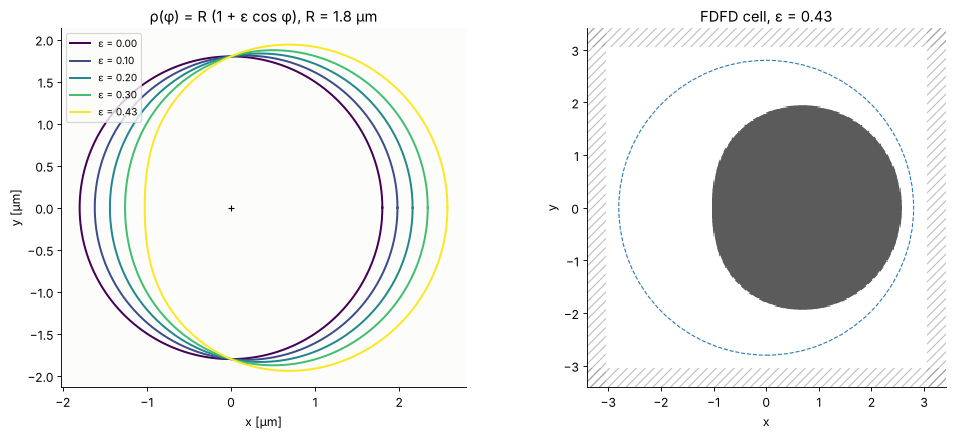

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
cmap = plt.get_cmap("viridis")
for e in (0.0, 0.1, 0.2, 0.3, 0.43):
    b = fdtd.Limacon((0, 0), R, e).boundary()
    axes[0].plot(b[:, 0], b[:, 1], color=cmap(e/0.43), lw=1.8, label=f"ε = {e:.2f}")
axes[0].plot(0, 0, "k+")
axes[0].set_aspect("equal"); axes[0].legend(fontsize=9, loc="upper left")
axes[0].set_xlabel("x [µm]"); axes[0].set_ylabel("y [µm]"); axes[0].set_title("ρ(φ) = R (1 + ε cos φ), R = 1.8 µm")
sim43 = cavity(0.43)
sim43.epsilon(1.6)
fplot.plot_structure(sim43, ax=axes[1])
axes[1].add_patch(plt.Circle((0, 0), rho_ff, fill=False, ls="--", color="#2a7ab9"))
axes[1].set_title("FDFD cell, ε = 0.43")
plt.tight_layout()

## 2. The WGM of the circle

The exact mode m = 20 of the first radial order (one intensity maximum
across the rim) from `analytical.disk_resonance`. The FDFD returns the
two degenerate standing waves $\cos(m\varphi)$ and $\sin(m\varphi)$ (in
some combination); the deformation keeps the mirror symmetry
$y \to -y$, so its modes are even or odd. We follow the **even** one,
the combination symmetric in y. The azimuthal number is checked on a
circle just inside the rim (`fdfd.circle_harmonics`).

exact:  wavelength 1.53754 µm, Q = 6.39e+13
FDFD:   wavelength 1.54147 µm (+3.9 nm), Q = 1.5e+07, m = 20
FDFD:   wavelength 1.54153 µm (+4.0 nm), Q = 5.05e+07, m = 20
14 s


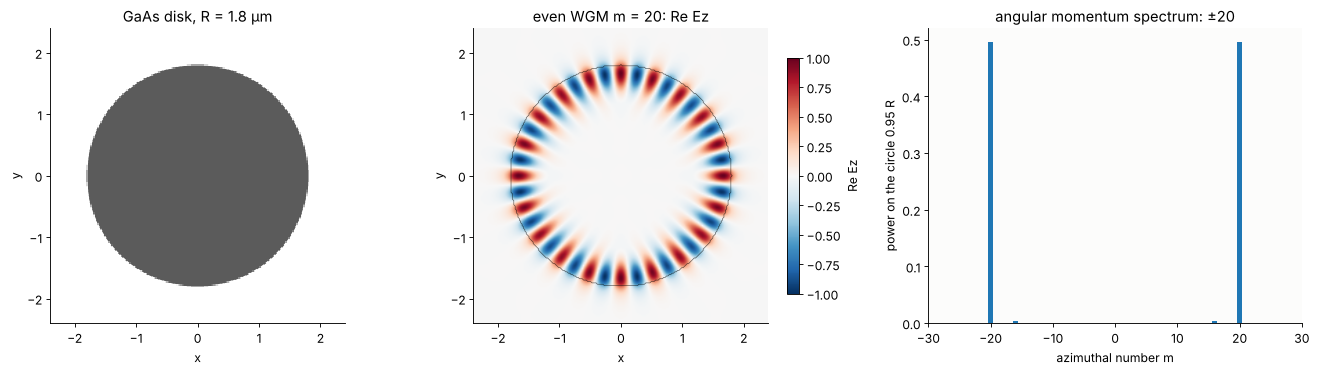

In [3]:
k_ex = an.disk_resonance(m_wgm, R, n_gaas, 1.54)
wl_ex, Q_ex = 2*np.pi/k_ex.real, k_ex.real/(-2*k_ex.imag)

t0 = time.perf_counter()
sim0 = cavity(0.0)
modes0 = sim0.resonances(wl_ex, n=6)


def azimuthal_number(r):
    mm, c = fdfd.circle_harmonics(r.field, 0.95*R)
    return abs(mm[np.argmax(np.abs(c))])


pair = [r for r in modes0 if azimuthal_number(r) == m_wgm][:2]
u_even = max((r.field.main + r.field.main[:, ::-1] for r in pair), key=np.linalg.norm)
start = pair[0]
start.field.fields["Ez"][0] = u_even/np.abs(u_even).max()
print(f"exact:  wavelength {wl_ex:.5f} µm, Q = {Q_ex:.3g}")
for r in pair:
    print(f"FDFD:   wavelength {r.wavelength:.5f} µm ({1e3*(r.wavelength - wl_ex):+.1f} nm), Q = {r.Q:.3g}, "
          f"m = {azimuthal_number(r)}")
print(f"{time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
fplot.plot_structure(sim0, ax=axes[0], show_pml=False)
axes[0].set_title("GaAs disk, R = 1.8 µm")
fplot.plot_field(start.field, "Ez", ax=axes[1], sim=sim0, part="real", title="even WGM m = 20: Re Ez")
mm, c = fdfd.circle_harmonics(start.field, 0.95*R)
axes[2].bar(mm, np.abs(c)**2/np.sum(np.abs(c)**2), width=0.8)
axes[2].set_xlim(-30, 30); axes[2].set_xlabel("azimuthal number m"); axes[2].set_ylabel("power on the circle 0.95 R")
axes[2].set_title("angular momentum spectrum: ±20")
for ax in axes[:2]:
    ax.set_xlim(-2.4, 2.4); ax.set_ylim(-2.4, 2.4)
plt.tight_layout()

The wavelength is off by 0.25 % at this cell size (21 cells per
wavelength in GaAs; it converges as $h^2$, notebook 66). The exact Q of
$6\cdot10^{13}$ is out of reach: the light that this mode leaks by
tunnelling is far weaker than what the staircase of the grid scatters out
of the rim, which caps the computed Q at about $10^7$ here. That floor
does not matter once the deformation lets the mode leak more than the
grid does.

## 3. Tracing the mode through the deformation

From $\varepsilon = 0$ to 0.43 in steps of 0.02: at each step the FDFD
eigenvalue problem is solved near the extrapolated complex frequency, and
the mode with the largest overlap with the previous one is kept
(`Simulation.resonance(like=...)`). Far field and directionality are
computed along the way. The directionality
$U = \int I(\varphi)\cos\varphi\,d\varphi / \int I(\varphi)\,d\varphi$
is 1 for all light into $\varphi = 0$ and 0 for symmetric emission.

23 cavities in 113 s; smallest overlap between steps 0.944
parity (1: even) between 1.0 and 1.0
ε = 0.00: wavelength 1.5415 µm, Q = 1.5e+07, U = +0.000
ε = 0.10: wavelength 1.5454 µm, Q = 3.55e+06, U = -0.050
ε = 0.20: wavelength 1.5569 µm, Q = 7.5e+06, U = +0.014
ε = 0.30: wavelength 1.5760 µm, Q = 2.52e+05, U = +0.088
ε = 0.40: wavelength 1.6027 µm, Q = 1.26e+04, U = +0.148
ε = 0.43: wavelength 1.6121 µm, Q = 6.46e+03, U = +0.170


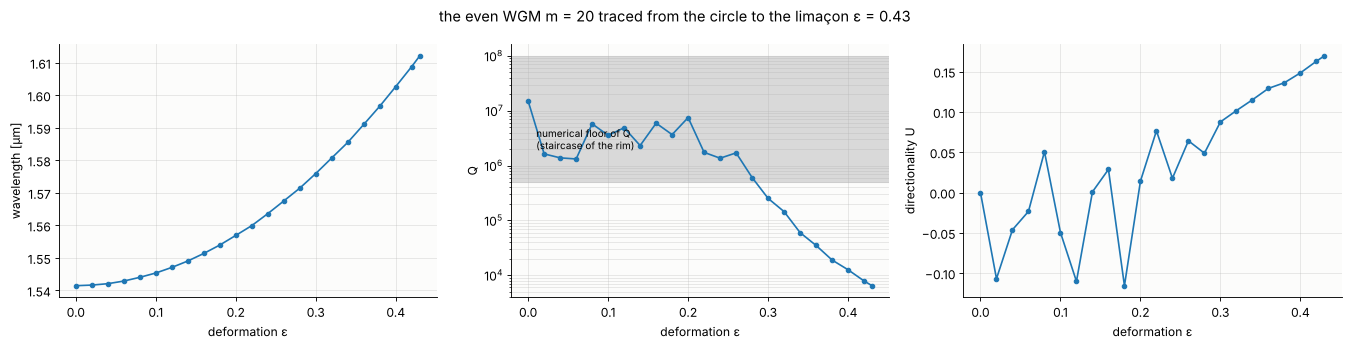

In [4]:
t0 = time.perf_counter()
trace, ffs, hist, overl = [start], [fdfd.farfield(start.field, rho_ff)], [start.omega], [1.0]
for eps in eps_list[1:]:
    guess = 2*np.pi/(2*hist[-1] - hist[-2]) if len(hist) > 1 else None
    r = cavity(eps).resonance(guess, like=trace[-1])
    overl.append(r.overlap(trace[-1]))
    trace.append(r)
    ffs.append(fdfd.farfield(r.field, rho_ff))
    hist.append(r.omega)
print(f"{len(eps_list)} cavities in {time.perf_counter() - t0:.0f} s; "
      f"smallest overlap between steps {min(overl):.3f}")
wl = np.array([r.wavelength for r in trace])
Q = np.array([r.Q for r in trace])
U = np.array([f.directionality() for f in ffs])
parity = np.array([np.vdot(r.field.main, r.field.main[:, ::-1]).real/np.vdot(r.field.main, r.field.main).real
                   for r in trace])
print("parity (1: even) between", parity.min().round(3), "and", parity.max().round(3))
for e, w_, q, u in zip(eps_list, wl, Q, U):
    if e in (0.0, 0.1, 0.2, 0.3, 0.4, 0.43):
        print(f"ε = {e:.2f}: wavelength {w_:.4f} µm, Q = {q:.3g}, U = {u:+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(eps_list, wl, "o-", ms=4)
axes[0].set_ylabel("wavelength [µm]")
axes[1].semilogy(eps_list, Q, "o-", ms=4)
axes[1].axhspan(5e5, 1e8, color="0.85", zorder=0)
axes[1].text(0.01, 2e6, "numerical floor of Q\n(staircase of the rim)", fontsize=9)
axes[1].set_ylabel("Q")
axes[2].plot(eps_list, U, "o-", ms=4)
axes[2].set_ylabel("directionality U")
for ax in axes:
    ax.set_xlabel("deformation ε"); ax.grid(alpha=0.3, which="both")
fig.suptitle("the even WGM m = 20 traced from the circle to the limaçon ε = 0.43")
plt.tight_layout()

The wavelength grows by about 70 nm: the path around the rim gets
longer. Q stays at the numerical floor up to $\varepsilon \approx 0.25$
(in reality it falls from $10^{13}$, but stays above what the grid can
resolve), then drops by three orders of magnitude to about $6\cdot10^3$
at $\varepsilon = 0.43$, which is still a good cavity. The emission
turns towards $\varphi = 0$ as the light starts to leave.

## 4. Near fields

$|E_z|$ on a logarithmic scale shows the light inside and the weak
emission outside; the cavity is outlined in each panel.

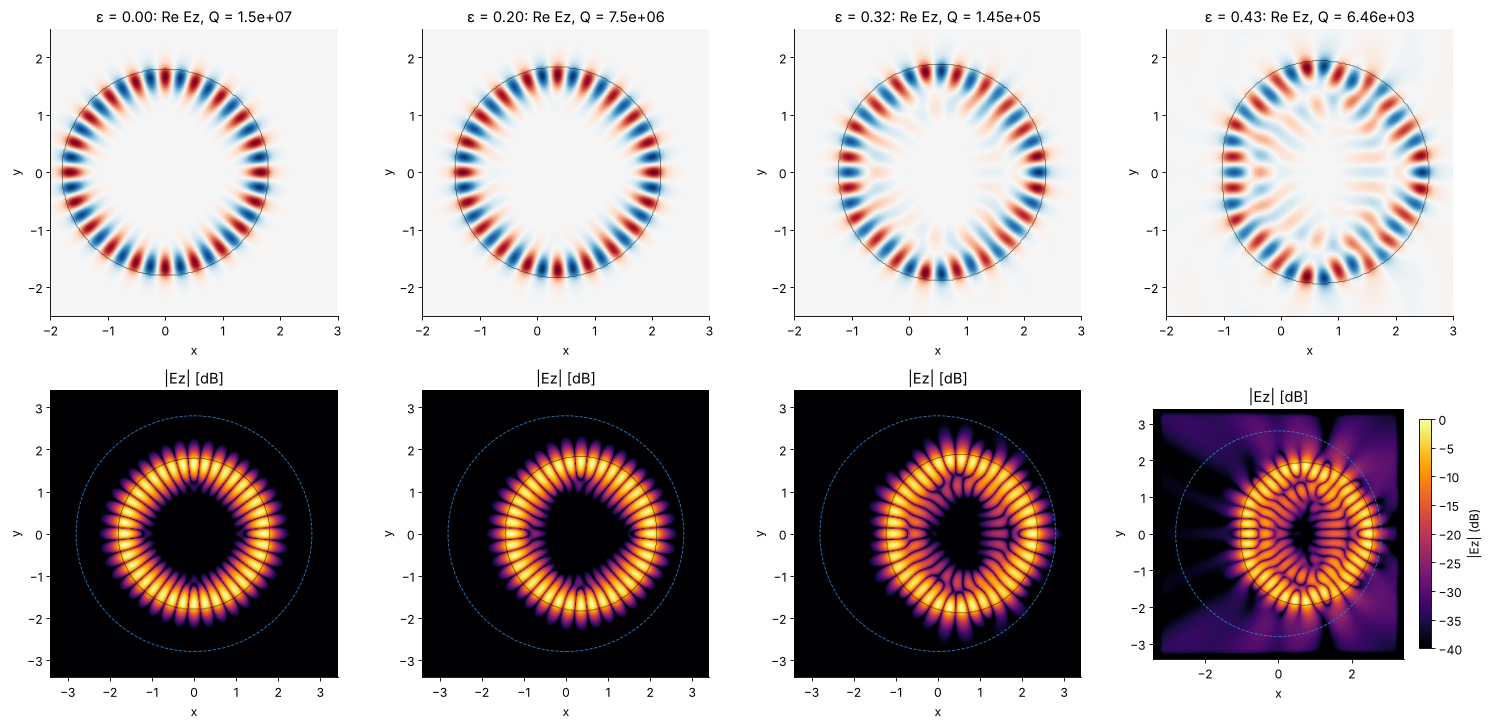

In [5]:
show = [0.0, 0.2, 0.32, 0.43]
fig, axes = plt.subplots(2, 4, figsize=(19, 9.2))
for col, e in enumerate(show):
    i = eps_list.index(e)
    r, s = trace[i], cavity(e)
    fplot.plot_field(r.field, "Ez", ax=axes[0, col], sim=s, part="real", colorbar=False,
                     title=f"ε = {e:.2f}: Re Ez, Q = {Q[i]:.3g}")
    axes[0, col].set_xlim(-2.0, 3.0); axes[0, col].set_ylim(-2.5, 2.5)
    fplot.plot_field(r.field, "Ez", ax=axes[1, col], sim=s, part="abs", log=True, colorbar=(col == 3),
                     title="|Ez| [dB]")
    axes[1, col].add_patch(plt.Circle((0, 0), rho_ff, fill=False, ls="--", color="#2a7ab9", lw=0.8))
plt.tight_layout()

The mode keeps its 2 × 20 lobes along the rim up to $\varepsilon \approx 0.3$;
then a pattern develops inside the cavity as the WGM mixes with other
modes. Outside, at −40 dB and below, the circle shows only the weak,
four-fold pattern that the square grid scatters out of the rim; the
deformed cavity sends out a beam to the right, along the axis, and weaker
light to the left.

## 5. Far fields

The far-field intensity (mean 1) of the traced mode for all deformations,
and polar plots at the four deformations shown above:

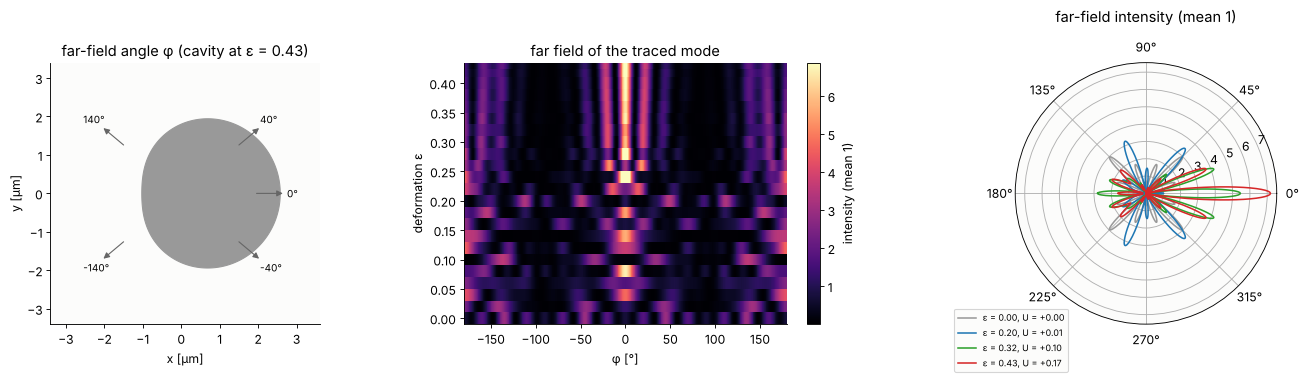

In [6]:
I_map = np.array([f.intensity for f in ffs])
phi = ffs[0].phi
fig = plt.figure(figsize=(18, 5))
ax0 = fig.add_subplot(1, 3, 1)
lim = fdtd.Limacon((0, 0), R, 0.43).boundary()
ax0.fill(lim[:, 0], lim[:, 1], color="0.6")
for a_deg in (0, 40, 140, -140, -40):
    a = np.radians(a_deg)
    ax0.annotate("", xy=(2.7*np.cos(a), 2.7*np.sin(a)), xytext=(1.9*np.cos(a), 1.9*np.sin(a)),
                 arrowprops=dict(arrowstyle="-|>", color="0.4"))
    ax0.text(3.0*np.cos(a) - 0.25, 3.0*np.sin(a) - 0.1, f"{a_deg}°", fontsize=9)
ax0.set_aspect("equal"); ax0.set_xlim(-3.4, 3.6); ax0.set_ylim(-3.4, 3.4)
ax0.set_title("far-field angle φ (cavity at ε = 0.43)"); ax0.set_xlabel("x [µm]"); ax0.set_ylabel("y [µm]")
ax1 = fig.add_subplot(1, 3, 2)
im = ax1.pcolormesh(np.degrees(phi), eps_list, I_map, shading="nearest", cmap="magma",
                    vmax=np.percentile(I_map[len(eps_list)//2:], 99.5))
plt.colorbar(im, ax=ax1, label="intensity (mean 1)")
ax1.set_xlabel("φ [°]"); ax1.set_ylabel("deformation ε"); ax1.set_title("far field of the traced mode")
ax2 = fig.add_subplot(1, 3, 3, projection="polar")
for e, c in zip(show, ("0.6", "C0", "C2", "C3")):
    f = ffs[eps_list.index(e)]
    ax2.plot(f.phi, f.intensity, color=c, lw=1.4, label=f"ε = {e:.2f}, U = {f.directionality():+.2f}")
ax2.set_title("far-field intensity (mean 1)", pad=16); ax2.legend(loc="lower left", fontsize=8, bbox_to_anchor=(-0.25, -0.2))
plt.tight_layout()

For small deformations the pattern is the speckle of a WGM that barely
radiates (and partly the grid's own scattering). From
$\varepsilon \approx 0.25$ on, as Q drops, one narrow beam at $\varphi = 0$
emerges, along the symmetry axis on the side of the largest radius, with
weaker lobes at about ±25° and near ±140°. The lobes cost directionality:
$U$ only reaches about 0.17 here, although the main beam carries by far
the strongest peak. In the ray picture of Wiersig and Hentschel, light escapes where
the rays that leak from the chaotic part of phase space hit the boundary
below the critical angle, and the escape directions concentrate on the
axis; at kR ≈ 7 the mode is still far from the ray limit, so the
diffraction of the narrow escape regions spreads the emission.

The angular momentum spectrum of the outgoing wave tells the same story.
For the circle, the m = ±20 of the mode itself hardly radiates (its Q
from tunnelling is $6\cdot10^{13}$); what leaves is the grid's
scattering, which couples m to m ± 4k (the square grid has a four-fold
symmetry): ±8, ±4, 0, ±12, ±16. The deformed cavity radiates into a
broad band of |m| up to about 15, which is what a narrow beam needs:

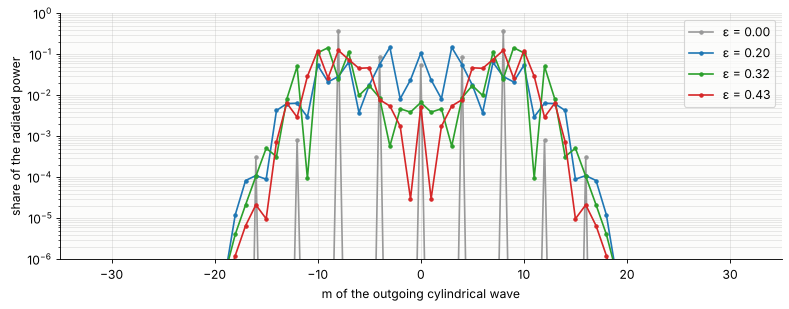

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for e, c in zip(show, ("0.6", "C0", "C2", "C3")):
    f = ffs[eps_list.index(e)]
    ax.semilogy(f.m, f.harmonic_power(), "o-", ms=3, color=c, label=f"ε = {e:.2f}")
ax.set_xlim(-35, 35); ax.set_ylim(1e-6, 1)
ax.set_xlabel("m of the outgoing cylindrical wave"); ax.set_ylabel("share of the radiated power")
ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout()

## 6. The other modes of the limaçon

The traced WGM is not the only resonance of the $\varepsilon = 0.43$
cavity near 1.6 µm. All modes (both parities) between 1.52 and 1.70 µm
with their Q and directionality, the traced one marked; the cavity is
the one drawn in section 1:

32 modes with Q > 30, 18 s


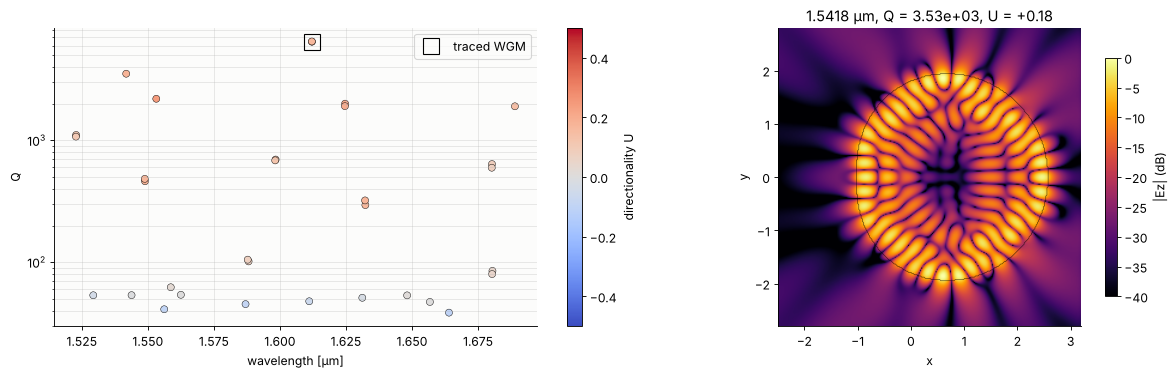

In [8]:
t0 = time.perf_counter()
s43 = cavity(0.43)
others = []
for guess in (1.54, 1.58, 1.62, 1.66):
    others += s43.resonances(guess, n=14, refine=0)
uniq = []
for r in sorted(others, key=lambda r: r.omega.real):
    if r.Q > 30 and 1.52 < r.wavelength < 1.70 and not any(abs(r.omega - q.omega) < 1e-5*abs(r.omega) for q in uniq):
        uniq.append(r)
oU = np.array([fdfd.farfield(r.field, rho_ff).directionality() for r in uniq])
print(f"{len(uniq)} modes with Q > 30, {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
sc = axes[0].scatter([r.wavelength for r in uniq], [r.Q for r in uniq], c=oU, cmap="coolwarm", vmin=-0.5, vmax=0.5,
                     s=40, edgecolors="k", linewidths=0.4)
axes[0].plot(wl[-1], Q[-1], "s", ms=14, mfc="none", mec="k", label="traced WGM")
axes[0].set_yscale("log"); axes[0].set_xlabel("wavelength [µm]"); axes[0].set_ylabel("Q")
axes[0].legend(); axes[0].grid(alpha=0.3, which="both"); plt.colorbar(sc, ax=axes[0], label="directionality U")
cands = [r for r in uniq if abs(r.wavelength - wl[-1]) > 1e-3]
best = max(cands, key=lambda r: r.Q*(fdfd.farfield(r.field, rho_ff).directionality() > 0.1))
fplot.plot_field(best.field, "Ez", ax=axes[1], sim=s43, part="abs", log=True,
                 title=f"{best.wavelength:.4f} µm, Q = {best.Q:.3g}, "
                       f"U = {fdfd.farfield(best.field, rho_ff).directionality():+.2f}")
axes[1].set_xlim(-2.5, 3.2); axes[1].set_ylim(-2.8, 2.8)
plt.tight_layout()

The traced WGM is the longest-lived mode in this band. All modes with
Q above 100 emit into φ = 0 (U between 0.1 and 0.25, red), only the
very leaky ones (Q ≈ 50) slightly backwards: for the long-lived modes
the direction of the emission is set by the shape, not by the individual
mode, which is the point of the limaçon. The right panel shows the
next-best mode with U > 0.1.

## 7. A check with the FDTD

An independent computation of the deformed cavity: a short current pulse
at the rim, on the symmetry axis (so it excites only even modes), in the
2D FDTD of `pyoptics.fdtd` on the same grid, and the frequencies and
Q of the ring-down from the matrix pencil method (`fdtd.resonances`).
The probe sits off the axis (cross), the source on it (amber):

FDTD: 67080 steps in 23 s
traced mode, FDFD: wavelength 1.61213 µm, Q = 6456
           FDTD: wavelength 1.61185 µm, Q = 6405  (difference -0.28 nm, -0.8 % in Q)
all ring-down poles: 1.6320 µm (Q 322), 1.6244 µm (Q 2022), 1.6118 µm (Q 6405), 1.5982 µm (Q 705), 1.5876 µm (Q 105), 1.5829 µm (Q 67)


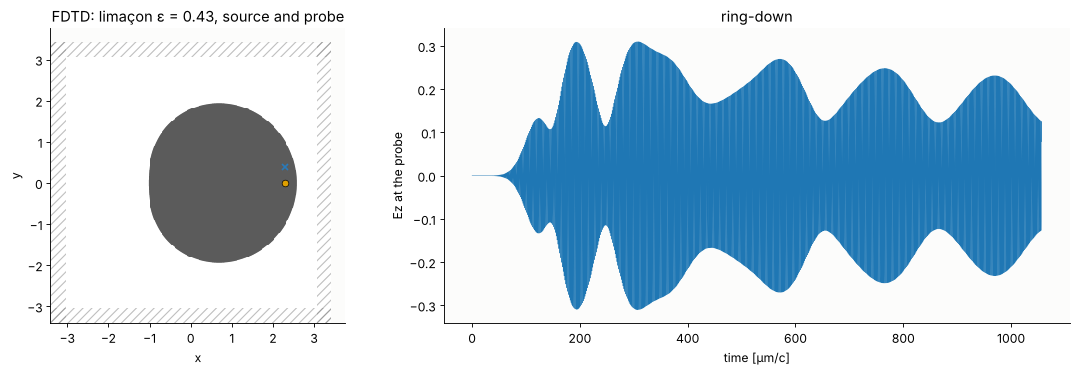

In [9]:
pulse = fdtd.GaussianPulse(wl[-1], bandwidth=0.01)
probe = fdtd.Probe((2.3, 0.4))
td = fdtd.Simulation(grid, [(fdtd.Limacon((0, 0), R, 0.43), gaas)], [fdtd.PointSource((2.3, 0.0), pulse)], [probe],
                     boundaries=fdtd.PML(16))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [0.8, 1.4]})
fplot.plot_structure(td, ax=axes[0])
axes[0].set_title("FDTD: limaçon ε = 0.43, source and probe")

t0 = time.perf_counter()
T = 2*pulse.delay + 800
td.run(time=T)
sel = probe.times > 2*pulse.delay
ring = fdtd.resonances(probe.values[sel], td.dt, t0=probe.times[sel][0], band=(1.5, 1.7), min_q=50)
print(f"FDTD: {int(T/td.dt)} steps in {time.perf_counter() - t0:.0f} s")
axes[1].plot(probe.times, probe.values, lw=0.4)
axes[1].set_xlabel("time [µm/c]"); axes[1].set_ylabel("Ez at the probe"); axes[1].set_title("ring-down")
plt.tight_layout()

j = int(np.argmin(np.abs(1/ring.frequency - wl[-1])))
print(f"traced mode, FDFD: wavelength {wl[-1]:.5f} µm, Q = {Q[-1]:.4g}")
print(f"           FDTD: wavelength {1/ring.frequency[j]:.5f} µm, Q = {ring.Q[j]:.4g}  "
      f"(difference {1e3*(1/ring.frequency[j] - wl[-1]):+.2f} nm, {100*(ring.Q[j]/Q[-1] - 1):+.1f} % in Q)")
print("all ring-down poles:", ", ".join(f"{1/f:.4f} µm (Q {q:.0f})" for f, q in zip(ring.frequency, ring.Q)))

The two methods agree on the traced mode to a fraction of a nanometre
and about 1 % in Q. The FDTD ring-down also shows the other even modes
the pulse excites; their wavelengths and Q are among those of section 6.
For a single mode of high Q the FDFD is the cheaper tool (one sparse
eigenvalue solve, with field and far field at once); the FDTD finds all
modes in a band from one run and gives the time-domain picture.

## Summary

* The m = 20 WGM of a GaAs disk (R = 1.8 µm, n = 3.3) moves from
  1.54 µm to 1.61 µm as the disk is deformed into a limaçon with
  $\varepsilon = 0.43$; its Q falls from beyond what the grid resolves
  to about $6\cdot10^3$.
* Its emission turns from the isotropic pattern of the circle into a
  narrow beam along the symmetry axis at φ = 0 (the side of the largest
  radius), with weaker lobes at about ±25° and ±140°; the directionality U reaches about
  0.17 at this small size parameter (kR ≈ 7).
* All modes of the deformed cavity with Q > 100 in the band share the
  beam direction; the traced WGM keeps the highest Q.
* FDFD and FDTD agree on the deformed cavity (wavelength to 0.3 nm, Q to 1 %).

Related: [66](66_fdfd_basics.ipynb) (FDFD basics), [60](60_fdtd_photonic_circuits.ipynb)
(ring resonators in the FDTD), [63](63_fdtd_devices.ipynb) (photonic
crystal cavities).

In [10]:
print(f"total run time of the notebook: {time.perf_counter() - t_start:.0f} s")

total run time of the notebook: 173 s


## References

- J. Wiersig and M. Hentschel, "Combining directional light output and ultralow loss in deformed microdisks", Phys. Rev. Lett. 100, 033901 (2008).
- C. Yan, Q. J. Wang, L. Diehl, M. Hentschel, J. Wiersig, N. Yu, C. Pflügl, F. Capasso, M. A. Belkin, T. Edamura, M. Yamanishi and H. Kan, "Directional emission and universal far-field behavior from semiconductor lasers with limaçon-shaped microcavity", Appl. Phys. Lett. 94, 251101 (2009).
- S. Shinohara, M. Hentschel, J. Wiersig, T. Sasaki and T. Harayama, "Ray-wave correspondence in limaçon-shaped semiconductor microcavities", Phys. Rev. A 80, 031801(R) (2009).
- Q. J. Wang, C. Yan, N. Yu, J. Unterhinninghofen, J. Wiersig, C. Pflügl, L. Diehl, T. Edamura, M. Yamanishi, H. Kan and F. Capasso, "Whispering-gallery mode resonators for highly unidirectional laser action", Proc. Natl. Acad. Sci. USA 107, 22407-22412 (2010).
- H. Cao and J. Wiersig, "Dielectric microcavities: Model systems for wave chaos and non-Hermitian physics", Rev. Mod. Phys. 87, 61-111 (2015).
- J. U. Nöckel and A. D. Stone, "Ray and wave chaos in asymmetric resonant optical cavities", Nature 385, 45-47 (1997).
- S. L. McCall, A. F. J. Levi, R. E. Slusher, S. J. Pearton and R. A. Logan, "Whispering-gallery mode microdisk lasers", Appl. Phys. Lett. 60, 289-291 (1992).
- T. Skauli, P. S. Kuo, K. L. Vodopyanov, T. J. Pinguet, O. Levi, L. A. Eyres, J. S. Harris, M. M. Fejer, B. Gerard, L. Becouarn and E. Lallier, "Improved dispersion relations for GaAs and applications to nonlinear optics", J. Appl. Phys. 94, 6447-6455 (2003).
- Y. Hua and T. K. Sarkar, "Matrix pencil method for estimating parameters of exponentially damped/undamped sinusoids in noise", IEEE Trans. Acoust. Speech Signal Process. 38, 814-824 (1990).